# Solve for the geodesic trajectory of a massive particle in Schwarzschild spacetime

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.animation import PillowWriter
from mpl_toolkits.mplot3d import Axes3D

# Units and integration array

In [256]:
M = 1.
#geometrized units 
G = 1.
c = 1.

l = 2*np.sqrt(12)*G*M/c

#tau is the integration parameter, dtau is the (proper!)time step
dtau = 0.01
taumax = 50000
tau = np.linspace(0,taumax,int(taumax/dtau + 1))



## Functions that will be used by the Class

$ H := \frac{1}{2} \left(\frac{e^2 -c^4}{c^2}\right) = \frac{\dot{r}^2}{2} + V_{eff}(l,r,M)$

$ V_{eff}(l,r,M) = \frac{l^2}{2r^2} - \frac{GMl^2}{c^2r^3} - \frac{GM}{r}$

In [257]:
V_eff = lambda l,r,M : (l**2.0)/(2*r**2.0) - (G*M)/r - (G*M*l**2.0)/((c**2.0)*(r**3.0))
r_V_eff = np.linspace(2*G*M/c**2, 100*G*M/c**2,1000)

$ \frac{d^2 r}{d \tau^2} = \frac{l^2}{r^3} - \frac{GM}{r^2} - \frac{3GMl^2}{c^2r^4}$ Equation of motion by taking second derivative of hamiltonian equation

$ e = c^2 \left( 1 - \frac{2GM}{c^2r}\right) \frac{dt}{d \tau}$ Conserved energy per unit mass

$ l = r^2 \frac{d \phi}{d \tau}$ Conserved angular momentum per unit mass

In [258]:
v_slope = lambda l,r,M:  (l**2.0)/(r**3.0) -(G*M)/(r**2.0) - (3*G*M*l**2.0)/((c**2.0)*(r**4.0))
t_slope = lambda e,r,M : (e/c**2.0)*(1 -(2*G*M)/(r*c**2.0) )**(-1.0)
phi_slope = lambda l,r : l/r**2.0

# Defining the Class of Test Particles

In [259]:
class Schwarzschild_potential_test_particle():
    def __init__(self, mass, angmom):
        self.mass = mass
        self.angmom = angmom
        #here mass is the mass of the black hole
        #angular momentum is the angular momentum of the test particle
        #the test particle has unit mass
        self.H = 0.0
        self.e = 0.0
        #H is the total energy/Hamiltonian of the test particle
        #e is the conserved energy per unit mass appearing in the Hamiltonian

        #unstable circular orbit
        self.r_min = (l**2.0)/(2*G*self.mass)*(1 - np.sqrt(1 - 12*(G*self.mass/(c*self.angmom))**2.0))
        self.H_min = (4*(G*self.mass)**2.0 - G*self.mass*self.r_min*c**2.0)/(2*self.r_min*(self.r_min*c**2.0 - 3*self.mass*G))

        #stable circular orbit
        self.r_max = (l**2.0)/(2*G*self.mass)*(1 + np.sqrt(1 - 12*(G*self.mass/(c*self.angmom))**2.0))
        self.H_max = (4*(G*self.mass)**2.0 - G*self.mass*self.r_max*c**2.0)/(2*self.r_max*(self.r_max*c**2.0 - 3*self.mass*G))
        
        
        
        #Arrays to store r,v,t and phi
        self.t = np.zeros(len(tau))
        self.r = np.zeros(len(tau))
        self.v = np.zeros(len(tau))
        self.phi = np.zeros(len(tau))
        
        #Arrays that will contain x and y positions
        self.x = np.zeros(len(tau))
        self.y = np.zeros(len(tau))
        
    def plot_potential(self,radius_array):
        plt.plot(radius_array,V_eff(self.angmom,radius_array,self.mass))
        plt.ylabel('Effective Potential')
        plt.xlabel('Distance')
        plt.ylim([self.H_max - 0.1*abs(self.H_max), self.H_max + 2*abs(self.H_max)])# elliptical orbits locator
        plt.show()

    def RK_4(self):
        for i in range(0,len(tau)-1):
        #start with (r[i],v[i]) and employ RK-4 algorithm to find the 4 slopes
    
            v_k1 = (dtau)*v_slope(self.angmom,self.r[i],self.mass)
            r_k1 = (dtau)*self.v[i]
            t_k1 = (dtau)*t_slope(self.e,self.r[i],self.mass)
            phi_k1 = (dtau)*phi_slope(self.angmom,self.r[i])

            r_d = self.r[i] + (r_k1/2.0)
            if r_d<=2*M:
                self.r[i+1] = 2*M
                self.phi[i+1] = self.phi[i]
                self.t[i+1] = np.infty
                self.v[i+1] = self.v[i]
                break

            v_d = self.v[i] + v_k1/2.0
    
            v_k2 = (dtau)*v_slope(self.angmom,r_d, self.mass)
            r_k2 = (dtau)*(v_d)
            t_k2 = (dtau)*t_slope(self.e,r_d,self.mass)
            phi_k2 = (dtau)*phi_slope(self.angmom,r_d)

            r_d = self.r[i] + (r_k2/2.0)
            if r_d<=2*M:
                self.r[i+1] = 2*M
                self.phi[i+1] = self.phi[i]
                self.t[i+1] = np.infty
                self.v[i+1] = self.v[i]
                break
            v_d = self.v[i] + v_k2/2.0
    
            v_k3 = (dtau)*v_slope(self.angmom,r_d,self.mass)
            r_k3 = (dtau)*(v_d)
            t_k3 = (dtau)*t_slope(self.e,r_d,self.mass)
            phi_k3 = (dtau)*phi_slope(self.angmom,r_d)

            r_d = self.r[i] + r_k3
            if r_d<=2*M:
                self.r[i+1] = 2*M
                self.phi[i+1] = self.phi[i]
                self.t[i+1] = np.infty
                self.v[i+1] = self.v[i]
                break
            v_d = self.v[i] + v_k3
    
            v_k4 = (dtau)*v_slope(self.angmom,r_d,self.mass)
            r_k4 = (dtau)*(v_d)
            t_k4 = (dtau)*t_slope(self.e,r_d,self.mass)
            phi_k4 = (dtau)*phi_slope(self.angmom,r_d)
    
    
            #then add the average slope increment
            self.v[i+1] = self.v[i] + (1.0/6.0)*(v_k1 + 2*v_k2 + 2*v_k3 + v_k4)
            self.r[i+1] = self.r[i] + (1.0/6.0)*(r_k1 + 2*r_k2 + 2*r_k3 + r_k4)
            self.t[i+1] = self.t[i] + (1.0/6.0)*(t_k1 + 2*t_k2 + 2*t_k3 + t_k4)
            self.phi[i+1] = self.phi[i] + (1.0/6.0)*(phi_k1 + 2*phi_k2 + 2*phi_k3 + phi_k4)
            
            #when particle reaches event horizon, just exit the algorithm
            if self.r[i+1]<=2*M:
                self.r[i+1] = 2*M
                self.phi[i+1] = self.phi[i]
                self.t[i+1] = np.infty
                self.v[i+1] = self.v[i]
                break
                
        self.x = self.r * np.cos(self.phi)
        self.y = self.r * np.sin(self.phi)
                

# Declaring an Instance of the Class

In [260]:
test_1 = Schwarzschild_potential_test_particle(M,l) #this will be stable circular
test_2 = Schwarzschild_potential_test_particle(M,l) #this will be elliptical
test_3 = Schwarzschild_potential_test_particle(M,l) #this will be scattering
test_4 = Schwarzschild_potential_test_particle(M,l) #this will be unstable circular
test_5 = Schwarzschild_potential_test_particle(M,l) #this will be inspiral


## Plotting the Effective Potential to Find e and H

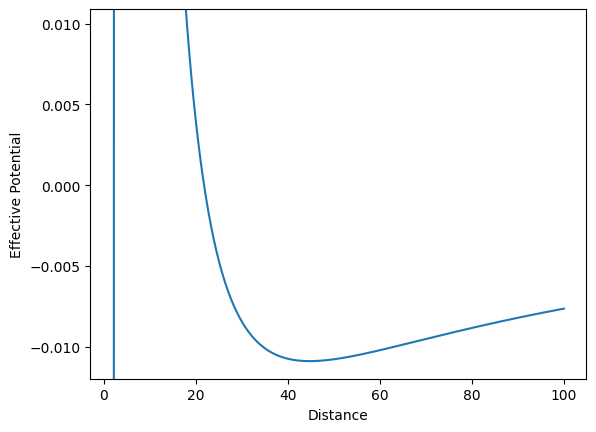

In [261]:
test_1.plot_potential(r_V_eff)

This helps me select what te total energy and the conserved energy per unit of mass 'e' should be when I use the Hamiltonian method to simulate a specific type of orbit(circular, elliptical, scattering or plunge). This is entered as new properties below

In [262]:

#stable circular orbit
test_1.H = test_1.H_max
test_1.e = np.sqrt(2*test_1.H*c**2.0 + c**4.0)
#take positive square root because want total energy to be positive(makes t and tau growth physical)

#elliptical orbit
test_2.H = -0.008
test_2.e = np.sqrt(2*test_2.H*c**2.0 + c**4.0)

#scattering orbit
test_3.H = +0.010
test_3.e = np.sqrt(2*test_3.H*c**2.0 + c**4.0)

#unstable circular orbit
test_4.H = test_4.H_min
test_4.e = np.sqrt(2*test_4.H*c**2.0 + c**4.0)

#inspiral orbit
test_5.H = (1.10)*test_4.H_min
test_5.e = np.sqrt(2*test_5.H*c**2.0 + c**4.0)

# The Runge-Kutta Fourth-Order Method

$ \dot{r} = \pm \sqrt{2(H-V_{eff}(l,r,M))}$

In [263]:
#Set the initial conditions, based on what type of orbit to simulate
test_1.r[0] = test_1.r_max
test_1.v[0] = 0.00
test_1.t[0] =  0.00
test_1.phi[0] = np.pi/3.0

test_2.r[0] = 45.00
test_2.v[0] = - np.sqrt(2*(test_2.H - V_eff(test_2.angmom,test_2.r[0],test_2.mass)))
test_2.t[0] =  0.00
test_2.phi[0] = np.pi/3.0

test_3.r[0] = 45.00
test_3.v[0] = - np.sqrt(2*(test_3.H - V_eff(test_3.angmom,test_3.r[0],test_3.mass)))
test_3.t[0] =  0.00
test_3.phi[0] = np.pi/3.0


test_4.r[0] = test_4.r_min
test_4.v[0] = 0.00
test_4.t[0] =  0.00
test_4.phi[0] = np.pi/3.

test_5.r[0] = 75.00
test_5.v[0] = - np.sqrt(np.abs(2*(test_5.H - V_eff(test_5.angmom,test_5.r[0],test_5.mass)))) 
test_5.t[0] =  0.00
test_5.phi[0] = np.pi/3.


In [264]:
#test_1.RK_4()
test_2.RK_4()
#test_3.RK_4()
#test_4.RK_4()
#test_5.RK_4()

# Error Analysis

In [265]:
Hamiltonian = lambda r, v,l,M : (1.00/2.00)*v**2.0 + V_eff(l,r,M)

In [266]:
def error_analysis(test_particle):
    print('Stable Circular radius:' +str(test_particle.r_max))
    print('Unstable Circular radius: '+ str(test_particle.r_min))
    print('minimum radial distance:' +str(np.min(test_particle.r)))
    print('maximum radial distance:'+str(np.max(test_particle.r)))
    print('maximum time:'+str(np.max(test_particle.t)))
    print('Hamiltonian input:'+str(test_particle.H))
    num_ham = Hamiltonian(test_particle.r, test_particle.v, test_particle.angmom, test_particle.mass)
    print('minimum of numerical Hamiltonian:'+str(np.min(num_ham)))
    print('maximum of numerical Hamiltonian:'+str(np.max(num_ham)))
    print('average absolute deviation of Hamiltonian:'+str(np.mean(np.abs(num_ham - test_particle.H))))

In [267]:
error_analysis(test_2)

Stable Circular radius:44.78460969082652
Unstable Circular radius: 3.2153903091734732
minimum radial distance:29.152357527295457
maximum radial distance:93.64993394458553
maximum time:51292.69189234262
Hamiltonian input:-0.008
minimum of numerical Hamiltonian:-0.008000000000000564
maximum of numerical Hamiltonian:-0.00799999999999972
average absolute deviation of Hamiltonian:2.1493344989190956e-16


In [268]:
test_2.r

array([45.        , 44.9992388 , 44.9984776 , ..., 29.15890805,
       29.15893519, 29.15896239])

# Plotting and Saving as gif file

In [269]:
len(test_2.r)

5000001

In [270]:
def plot_frame(index, ax, angle1, angle2):
    
    #mesh coordinates
    radius = np.linspace(2*G*M/c**2,120*G*M/c**2,1000)
    azimuth = np.linspace(0,2*np.pi,1000)
    radius, azimuth = np.meshgrid(radius, azimuth)
    X = radius*np.cos(azimuth)
    Y = radius*np.sin(azimuth)
    Z = -(np.sqrt(X**2.0 + Y**2.0)**(-0.1))

    #height of particle, living on the mesh
    test_2.z = -(np.sqrt(test_2.x**2.0 + test_2.y**2.0)**(-0.1))

    #plot
    ax.plot_surface(X,Y,Z, linewidth=0, alpha =0.5)
    ax.scatter(test_2.x[index], test_2.y[index], test_2.z[index], c ='red', s =50)
    ax.plot(test_2.x[:index+1],test_2.y[:index+1], test_2.z[:index+1], c ='red', linestyle='dashed', linewidth=3)
    ax.scatter(0,0,-(np.sqrt(np.min(test_2.r)**2.0)**(-0.1)),c='white', s =500)

    #aesthetics
    ax.set_axis_off()
    ax.view_init(angle1, angle2)
  




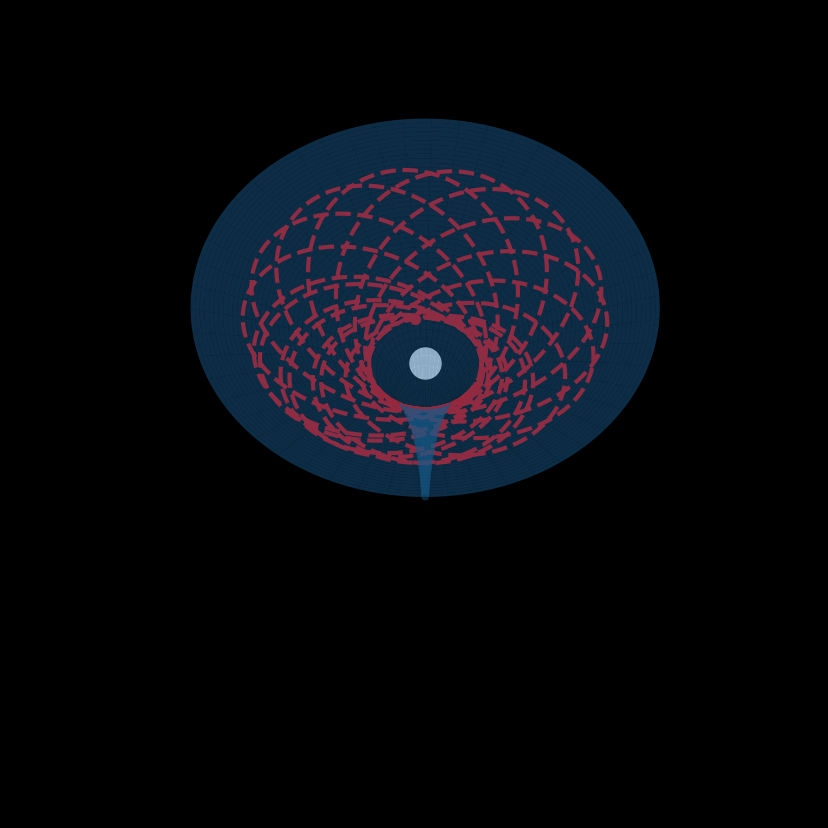

In [271]:

fig = plt.figure()

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_facecolor('black')
spacetime = plt.subplot(1,1,1, projection='3d')
spacetime.set_facecolor('black')
plot_frame(len(test_2.r)-1, spacetime, 55, 45)


In [272]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

In [274]:
len(tau)/20000

250.00005

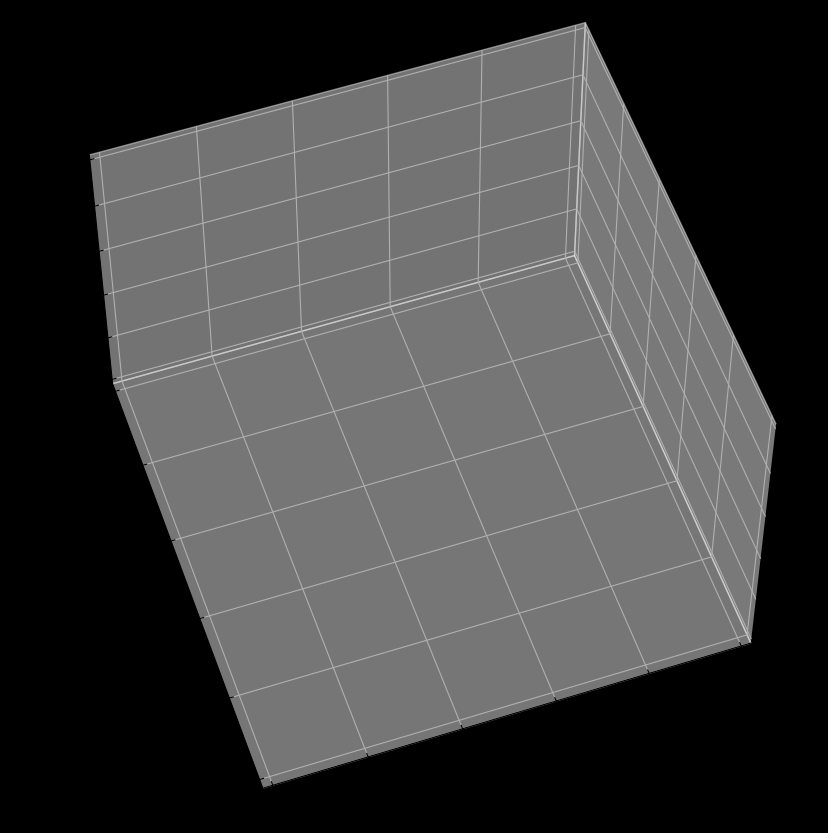

In [276]:
fig = plt.figure()

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_facecolor('black')
spacetime = plt.subplot(1,1,1, projection='3d')
spacetime.set_facecolor('black')

view_angle1 = 0
view_angle2 = 0

with writer.saving(fig, 'elliptical_geodesic_particle.gif',100):
     for i in range(0,len(tau)):
        if i%20000==0:
            if view_angle1<55:
                view_angle1= view_angle1 + 0.5 
            view_angle2 = view_angle2 + 1
            plot_frame(i, spacetime, view_angle1, view_angle2)
            writer.grab_frame()
            plt.cla()